In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
# read in data, then create dictionary to work with
# in increments of 10: 37 - 107, then 137, 150

frequencies = [37, 47, 57, 67, 77, 87, 97, 107, 137, 150]
data = {}

for freq in frequencies: 
    temp_df = pd.read_csv(f"{freq}k_freq.txt", sep =r"\s+") # utilize regex. why? 
    # print(temp_df)
    data[f"{freq}k"] = {"time": temp_df["time"], "potential_1": temp_df["potential_1"], "potential_2": temp_df["potential_2"]}



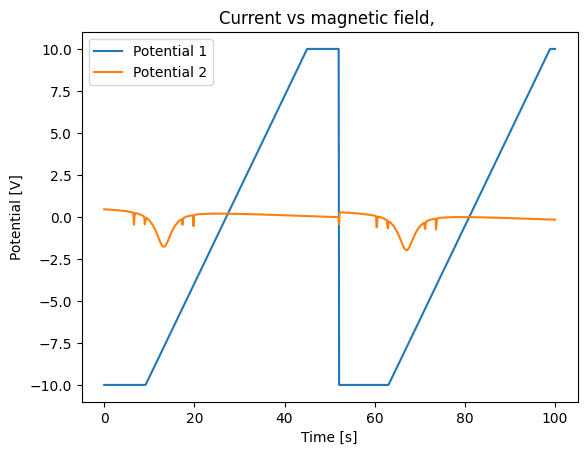

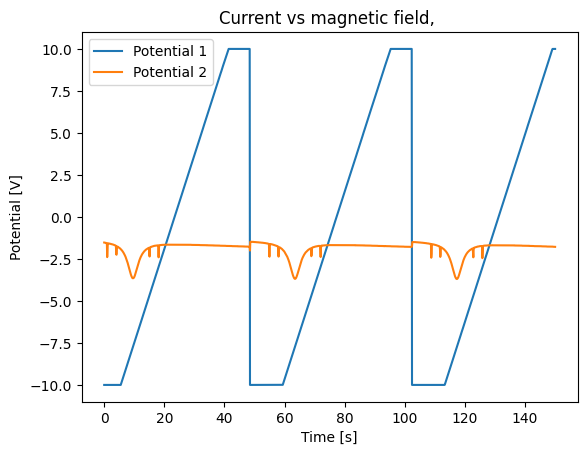

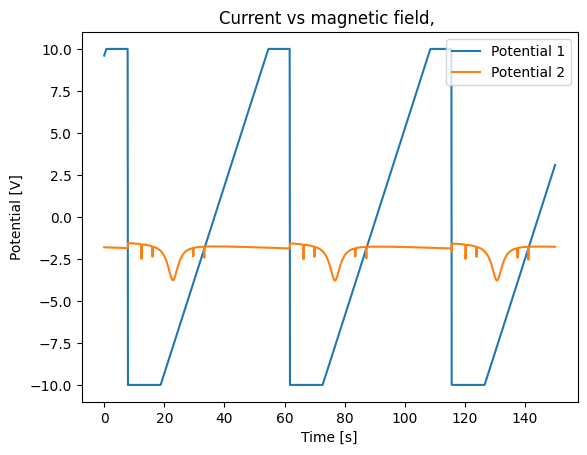

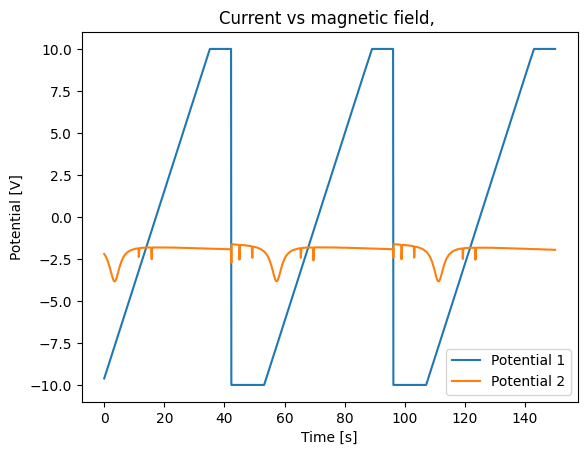

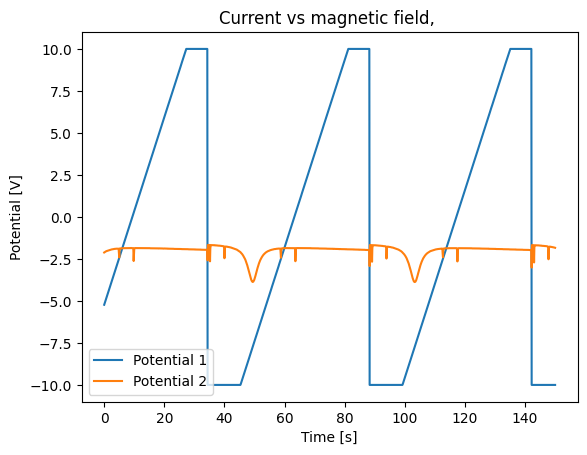

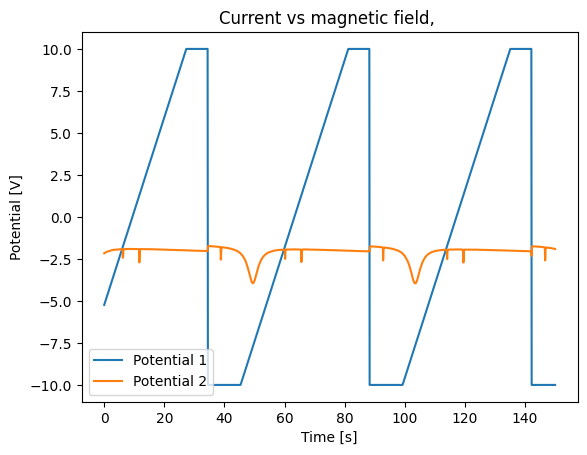

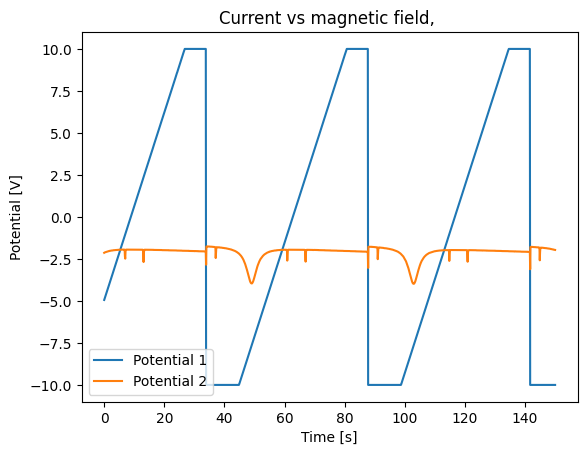

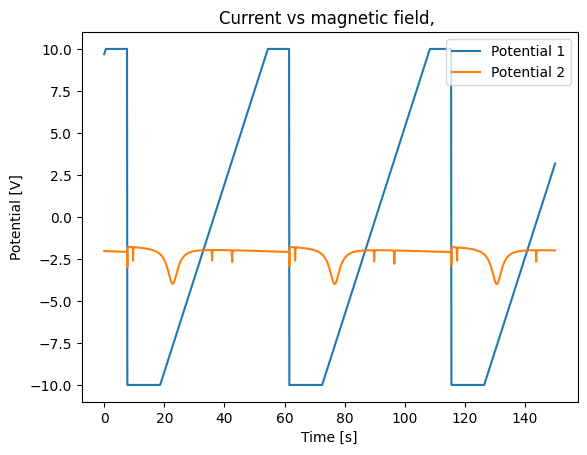

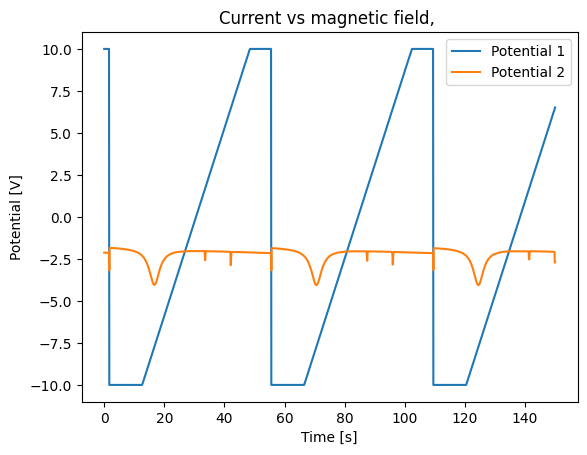

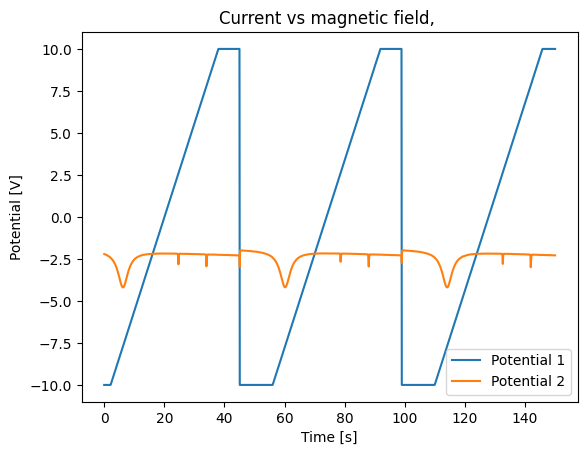

In [4]:
for freq in frequencies:
    fig, ax = plt.subplots()
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_1"], label = "Potential 1")
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_2"], label = "Potential 2")
    ax.legend()
    ax.set_title(f"Current vs magnetic field, ")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Potential [V]")

In [5]:
constant = 8.991e-3
resistance = 50 # ohms
turns = 11
mean_radius = 0.1639 # meters
N_over_R = turns/mean_radius


for freq in frequencies: 
    data[f"{freq}k"]["current"] = data[f"{freq}k"]["potential_1"]/resistance
    data[f"{freq}k"]["B_field"] = (8.991e-3)*(data[f"{freq}k"]["current"])*N_over_R

print(data["37k"]["B_field"])


0      -0.120685
1      -0.120685
2      -0.120685
3      -0.120685
4      -0.120685
          ...   
996     0.120681
997     0.120681
998     0.120681
999     0.120681
1000    0.120681
Name: potential_1, Length: 1001, dtype: float64


/var/folders/ks/2tn86v4j71s3_vztrw3j5f740000gn/T/ipykernel_64372/3899258520.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


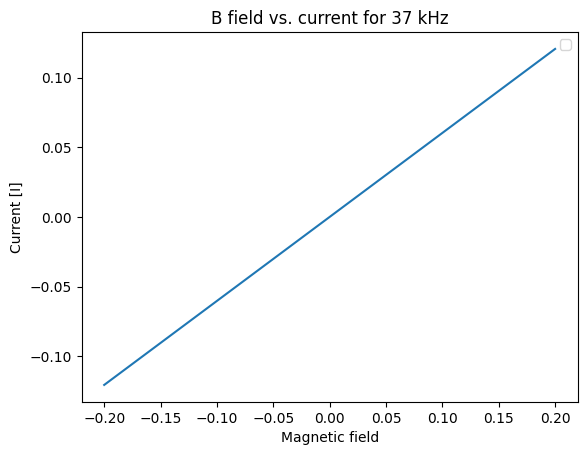

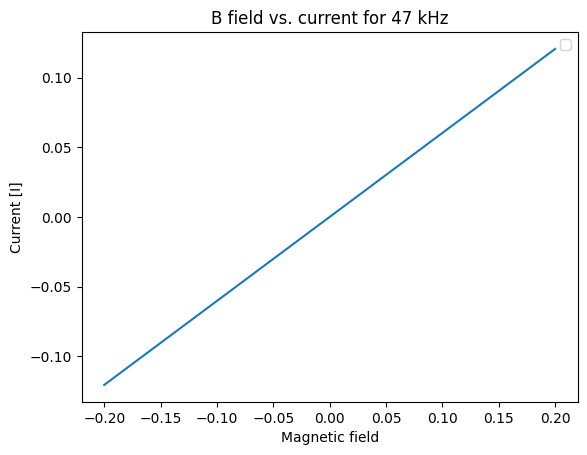

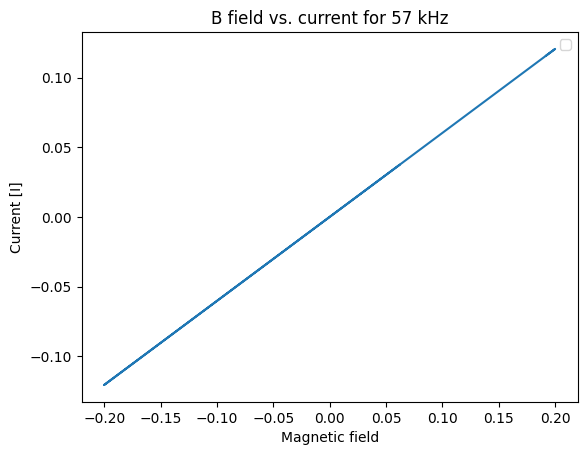

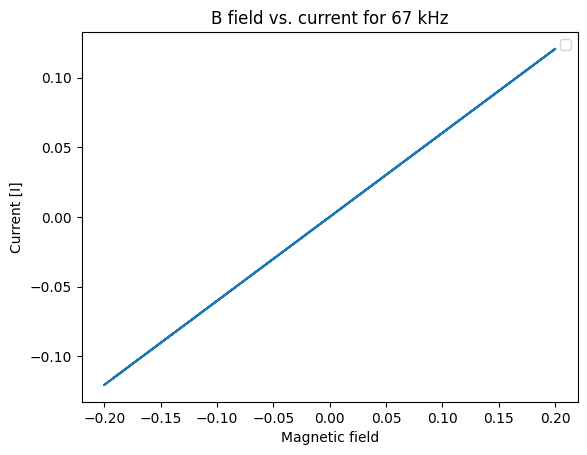

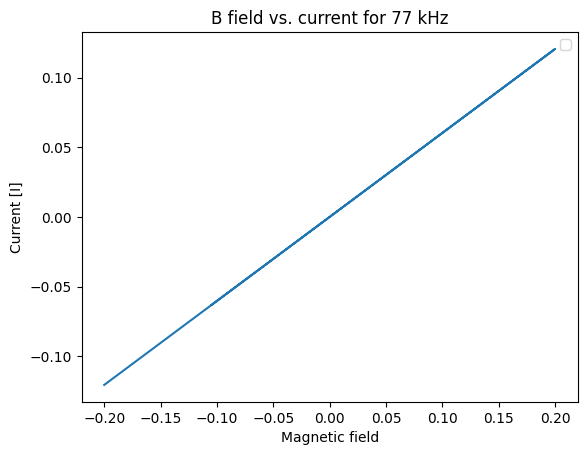

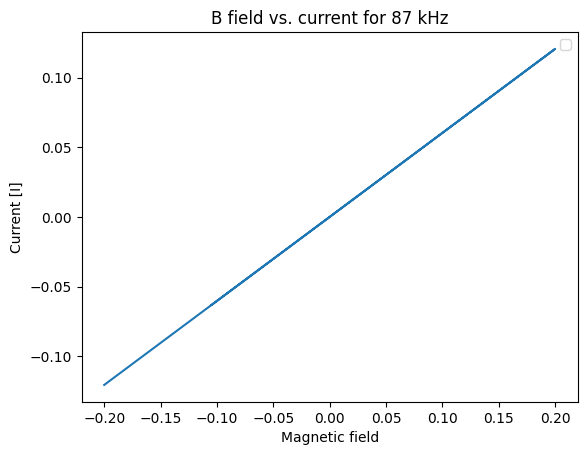

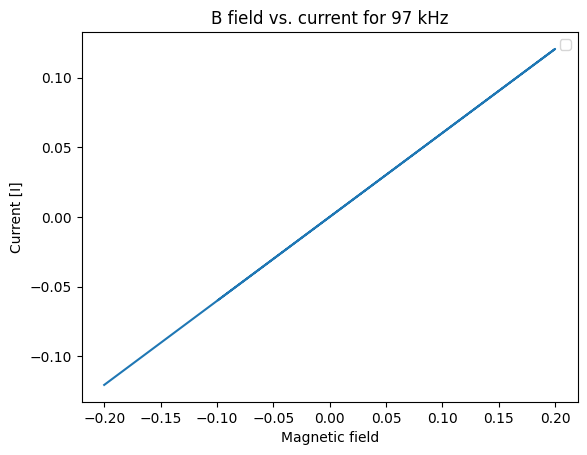

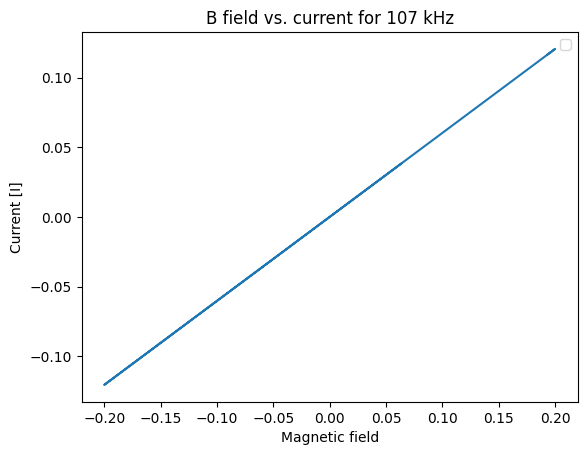

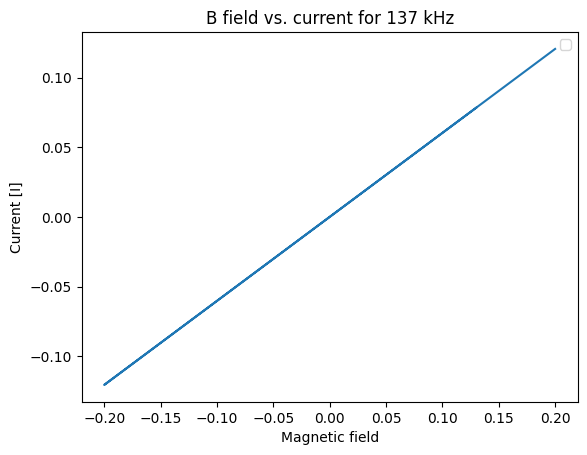

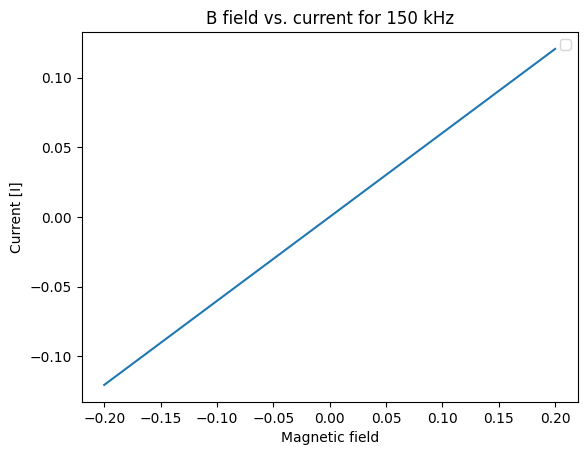

In [6]:
for freq in frequencies:
    fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["B_field"], label = "B_field")
    ax.plot(data[f"{freq}k"]["current"], data[f"{freq}k"]["B_field"])
    ax.legend()
    ax.set_title(f"B field vs. current for {freq} kHz")
    ax.set_xlabel("Magnetic field")
    ax.set_ylabel("Current [I]")

In [7]:
from sklearn.linear_model import LinearRegression
all_slopes = []
all_intercepts = []

for freq in frequencies:
    current_temp = data[f"{freq}k"]["current"]
    current_temp = current_temp.to_numpy().reshape(-1, 1) # -1 for determining the shape of the passed current_temp, 
                                                          # 1 is the amount of columns is reshapes to; for sklearn, one column per input
    B_field_temp = data[f"{freq}k"]["B_field"]
    B_field_temp = B_field_temp.to_numpy()
    # print(type(B_field_temp))
    fit = LinearRegression().fit(current_temp, B_field_temp)

    all_slopes.append(fit.coef_[0])
    all_intercepts.append(fit.intercept_)

    # fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["current"], data[f"{freq}k"]["B_field"], label = f"y = {fit.coef_[0]:0.3f}x + {fit.intercept_}")
    # ax.set_title(f"Magnetic field vs. current for {freq} Hz")
    # ax.set_xlabel("Magnetic field")
    # ax.set_ylabel("Current")
    # ax.grid()
    # ax.legend()

print(np.average(all_slopes))



0.6034228187919467


In [8]:
from scipy.stats import linregress


all_slopes = []
all_intercepts = []
fit_errors = []

for freq in frequencies:
    current_temp = data[f"{freq}k"]["current"]
    current_temp = current_temp.to_numpy()
    B_field_temp = data[f"{freq}k"]["B_field"]
    B_field_temp = B_field_temp.to_numpy()
    # print(type(B_field_temp))
    fit = linregress(current_temp, B_field_temp)
    all_slopes.append(fit.slope)
    all_intercepts.append(fit.intercept)
    fit_errors.append(fit.stderr)
    print(f"{freq}k: slope = {fit.slope}, fit error = {fit.stderr}")


37k: slope = 0.6034228187919464, fit error = 2.844848202049172e-10
47k: slope = 0.6034228187919468, fit error = 0.0
57k: slope = 0.6034228187919467, fit error = 0.0
67k: slope = 0.6034228187919465, fit error = 0.0
77k: slope = 0.6034228187919463, fit error = 3.284399848291198e-10
87k: slope = 0.603422818791946, fit error = 4.6448428097095476e-10
97k: slope = 0.6034228187919466, fit error = 0.0
107k: slope = 0.6034228187919463, fit error = 0.0
137k: slope = 0.6034228187919465, fit error = 0.0
150k: slope = 0.6034228187919465, fit error = 0.0


In [9]:
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def gaussian_with_linear_bg(x, a, mu, sigma, c0, c1):
    return a * np.exp(-0.5((x-mu)/sigma)**2 + c0 + c1*x)

# x = data
# a = peak amplitude
# mu = peak location
# sigma = peak spread
# c0, c1: linear background

peaks, properties = find_peaks(y, prominence=50, width=2) 
# find_peaks returns the peak locations as an array, 
# as well as a dictionary of those peak properties

locations = []

for p in peaks:
    fitting_window = int(properties["widths"][list(peaks).index(p) * 2]) # have the fitting window be double the peak width
    low, high = max(p - w, 0), min(p + w, len(y)) # have the low and high fit guesses be the peak location +/- width
    p0 = [y[p], x[p], x[1] - x[0], y[low], 0] # inital guesses in the order of x, a, mu, sigma, c0, c1
    popt, pcov = curve_fit(gaussian_with_linear_bg, x[low:hi], y[low:hi], p0=p0)
    locations.append((popt[1], np.sqrt[1,1]))

print(locations)

<>:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
<>:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
/var/folders/ks/2tn86v4j71s3_vztrw3j5f740000gn/T/ipykernel_64372/4259227435.py:5: SyntaxWarning: 'float' object is not callable; perhaps you missed a comma?
  return a * np.exp(-0.5((x-mu)/sigma)**2 + c0 + c1*x)


NameError: name 'y' is not defined

[np.int64(90), np.int64(173), np.int64(173), np.int64(198), np.int64(198), np.int64(521), np.int64(521), np.int64(604), np.int64(604), np.int64(629), np.int64(629), np.int64(712), np.int64(712), np.int64(736), np.int64(736)]
[np.int64(41), np.int64(151), np.int64(151), np.int64(181), np.int64(181), np.int64(485), np.int64(485), np.int64(550), np.int64(550), np.int64(580), np.int64(580), np.int64(689), np.int64(689), np.int64(720), np.int64(720), np.int64(1088), np.int64(1088), np.int64(1118), np.int64(1118), np.int64(1228), np.int64(1228), np.int64(1258), np.int64(1258)]
[np.int64(161), np.int64(296), np.int64(296), np.int64(333), np.int64(333), np.int64(663), np.int64(663), np.int64(699), np.int64(699), np.int64(835), np.int64(835), np.int64(872), np.int64(872), np.int64(1202), np.int64(1202), np.int64(1239), np.int64(1239), np.int64(1375), np.int64(1375), np.int64(1411), np.int64(1411)]
[np.int64(158), np.int64(423), np.int64(423), np.int64(450), np.int64(450), np.int64(493), np.int6

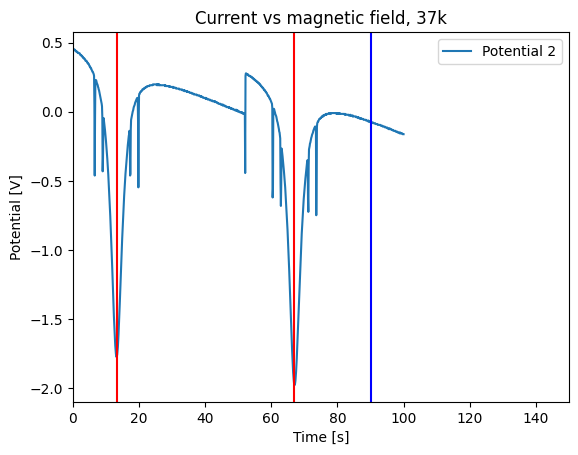

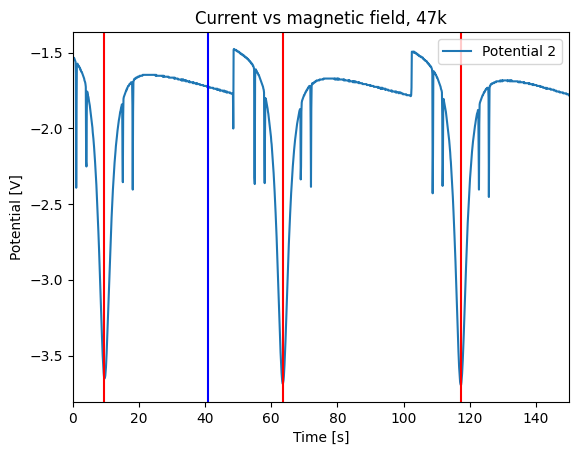

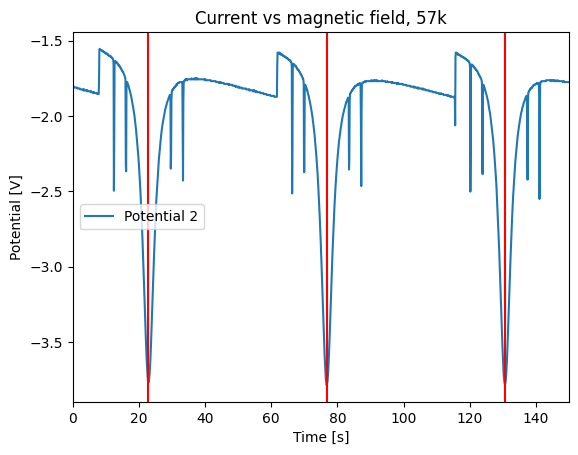

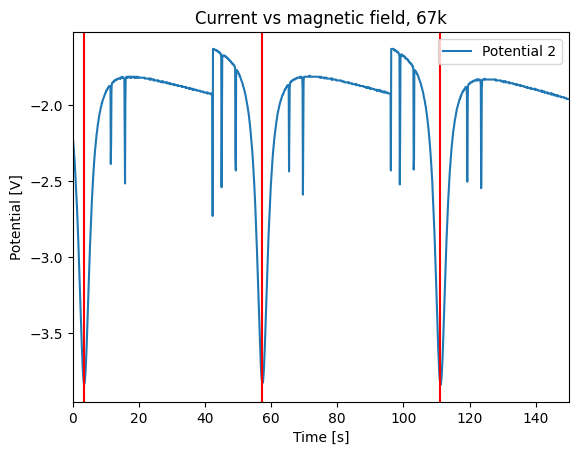

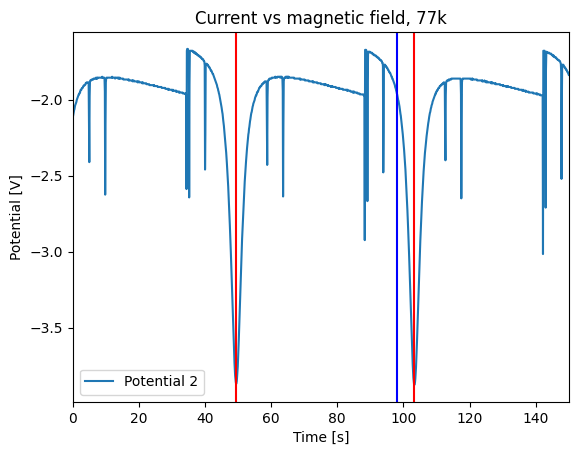

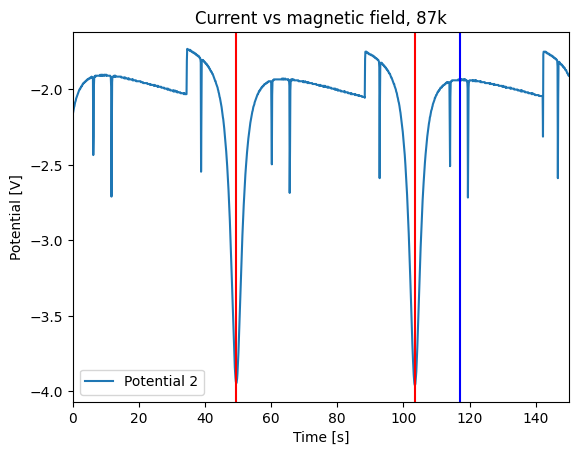

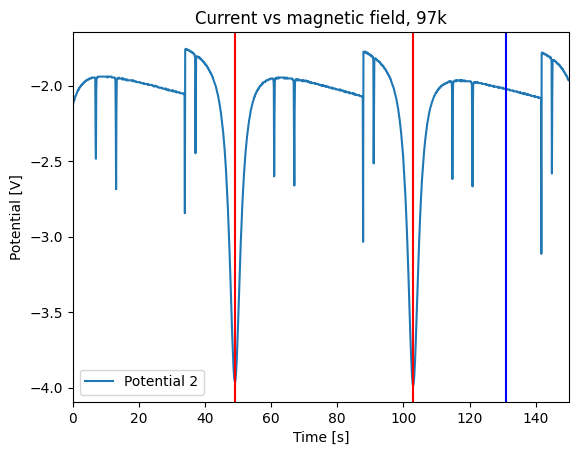

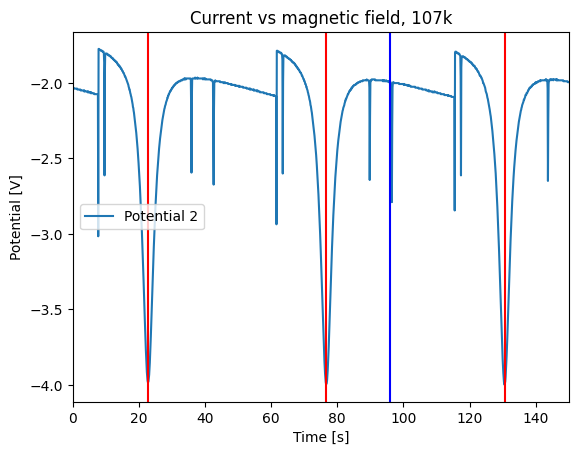

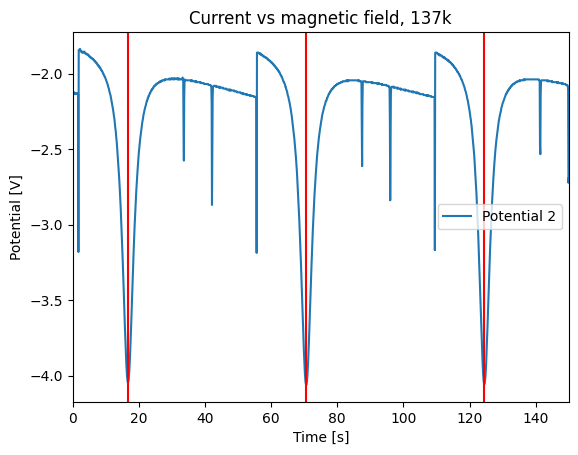

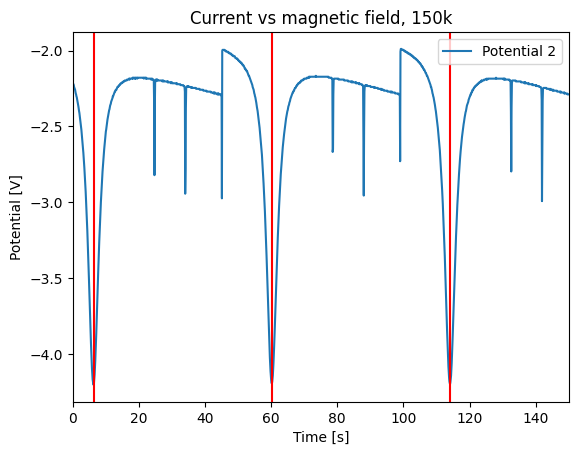

In [24]:
stored_currents = []
stored_frequencies = []

all_transition_peaks = []

for freq in frequencies:
    data_temp = data[f"{freq}k"]["potential_2"]
    zero_field_peaks, zero_field_properties = find_peaks(-data_temp, prominence=1, width = 20)

    small_peaks, small_peak_properties = find_peaks(-data_temp, prominence=0.3, width=(None, 10))
    # print(peaks)
    temp_transition_peak_holder = []

    resonance_peaks = []
    for i, p in enumerate(small_peaks):
        right_bound  = zero_field_peaks[i + 1] if i + 1 < len(zero_field_peaks) else len(-data_temp)
        location = small_peaks[(small_peaks > p) & (small_peaks < right_bound)]   # spikes between this dip and the next
        all_transition_peaks.extend(location[:2])                       # first two only
        # print(transition_peaks)
        temp_transition_peak_holder.extend(location[:2])

    print(temp_transition_peak_holder)

    

    fig, ax = plt.subplots()
    # ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_1"], label = "Potential 1")
    ax.plot(data[f"{freq}k"]["time"], data[f"{freq}k"]["potential_2"], label = "Potential 2")
    ax.legend()
    for p in zero_field_peaks:
        ax.axvline(x = data[f"{freq}k"]["time"][p], color = "red", label = "Zero field resonance")

    for t in temp_transition_peak_holder:
        ax.axvline(x = t, color = "blue", label = "Isotope resonances")
    
    ax.set_title(f"Current vs magnetic field, {freq}k")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Potential [V]")
    ax.set_xlim(0,150)

    # for p in peaks:
    #     stored_currents.append((data[f"{freq}k"]["current"][p])/resistance)
    #     stored_frequencies.append(freq)

    

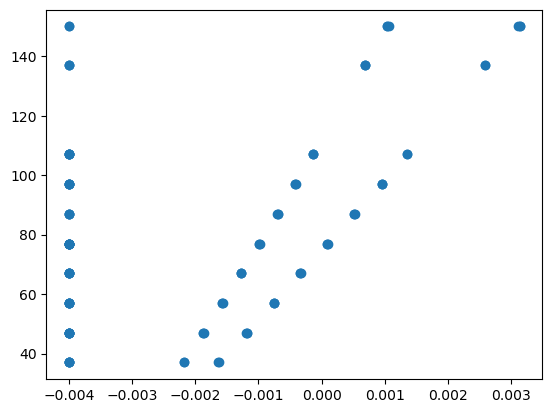

In [ ]:
fig, ax  = plt.subplots()
ax.scatter(stored_currents, stored_frequencies)

In [35]:
first_isotope_currents = []
first_isotope_frequencies = []

second_isotope_currents = []
second_isotope_frequencies = []

first_isotope = []
second_isotope = []

for freq in frequencies:
    t = np.asarray(data[f"{freq}k"]["time"])
    y = np.asarray(data[f"{freq}k"]["potential_2"])
    current = np.asarray(data[f"{freq}k"]["current"])

    zero_field_peaks, _ = find_peaks(-y, prominence=1, width=20)
    small_peaks, _ = find_peaks(-y, prominence=0.3, width=(None, 10))

    #     stored_currents.append((data[f"{freq}k"]["current"][p])/resistance)
    #     stored_frequencies.append(freq)

    transition_peaks = []
    for i, z in enumerate(zero_field_peaks):
        right_bound = zero_field_peaks[i + 1] if i + 1 < len(zero_field_peaks) else len(y)
        after = small_peaks[(small_peaks > z) & (small_peaks < right_bound)]
        transition_peaks.extend(after[:2])
        temp_first_isotope = transition_peaks[::2]
        for t in temp_first_isotope:
            first_isotope_currents.append((data[f"{freq}k"]["current"][t])/resistance)
            first_isotope_frequencies.append(freq)

        temp_second_isotope = transition_peaks[1::2]
        for s in temp_second_isotope:
            second_isotope_currents.append((data[f"{freq}k"]["current"][s])/resistance)
            second_isotope_frequencies.append(freq)
        first_isotope.extend(transition_peaks[::2])
        second_isotope.extend(transition_peaks[1::2])

    # transition_peaks = np.array(transition_peaks, dtype=int)

    # print(freq, t[transition_peaks])   # resonance times

    # fig, ax = plt.subplots()
    # ax.plot(t, y, label="Potential 2", color = "black")
    # for k, z in enumerate(zero_field_peaks):
    #     ax.axvline(t[z], color="red", label="Zero field resonance" if k == 0 else None, lw = 0.8)
    # for k, p in enumerate(transition_peaks):
    #     ax.axvline(t[p], color="blue", label="Isotope resonances" if k == 0 else None, lw = 0.8)

    # ax.legend()
    # ax.set_title(f"Potential vs time, {freq} kHz")
    # ax.set_xlabel("Time [s]")
    # ax.set_ylabel("Potential [V]")
    # ax.set_xlim(0, 150)
    # ax.grid

    # for p in first_isotope:
    #     stored_currents.append((data[f"{freq}k"]["current"][p])/resistance)
    #     stored_frequencies.append(freq)

    # for the analysis step, convert to current at each resonance:
    # current = np.asarray(data[f"{freq}k"]["current"])
    # for p in transition_peaks:
    #     stored_currents.append(current[p] / resistance)
    #     stored_frequencies.append(freq)


print(first_isotope,"\n", second_isotope, "\n", first_isotope_currents)

[np.int64(173), np.int64(173), np.int64(712), np.int64(151), np.int64(151), np.int64(689), np.int64(151), np.int64(689), np.int64(1228), np.int64(296), np.int64(296), np.int64(835), np.int64(296), np.int64(835), np.int64(1375), np.int64(115), np.int64(115), np.int64(654), np.int64(115), np.int64(654), np.int64(1193), np.int64(588), np.int64(588), np.int64(1127), np.int64(602), np.int64(602), np.int64(1141), np.int64(609), np.int64(609), np.int64(1148), np.int64(359), np.int64(359), np.int64(898), np.int64(359), np.int64(898), np.int64(1437), np.int64(336), np.int64(336), np.int64(875), np.int64(336), np.int64(875), np.int64(1414), np.int64(247), np.int64(247), np.int64(786), np.int64(247), np.int64(786), np.int64(1326)] 
 [np.int64(198), np.int64(198), np.int64(736), np.int64(181), np.int64(181), np.int64(720), np.int64(181), np.int64(720), np.int64(1258), np.int64(333), np.int64(333), np.int64(872), np.int64(333), np.int64(872), np.int64(1411), np.int64(158), np.int64(158), np.int64(6

Text(0, 0.5, 'Frequency [kHz]')

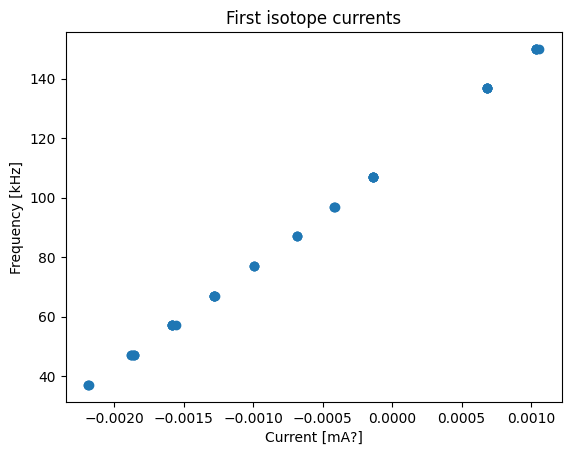

In [40]:
fig, ax = plt.subplots()
ax.scatter(first_isotope_currents, first_isotope_frequencies)
ax.set_title("First isotope currents")
ax.set_xlabel("Current [mA?]")
ax.set_ylabel("Frequency [kHz]")

Text(0, 0.5, 'Frequency [kHz]')

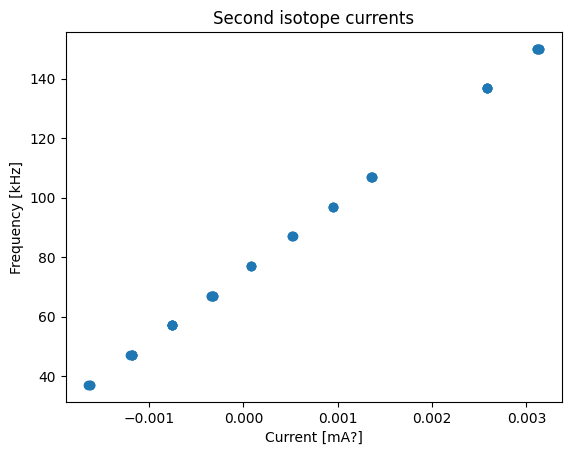

In [41]:
fig, ax = plt.subplots()
ax.scatter(second_isotope_currents, second_isotope_frequencies)
ax.set_title("Second isotope currents")
ax.set_xlabel("Current [mA?]")
ax.set_ylabel("Frequency [kHz]")